In [2]:
import cv2
import tensorflow as tf
import numpy as np
from collections import deque


Display Model's Prediction

In [ ]:
labels=['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T','U','V','W','X','Y','Z','del','ok','space']
len(labels)

In [ ]:
import mediapipe as mp
import cv2
import numpy as np
from collections import deque


letter_model = tf.keras.models.load_model('/home/maries/Development/Project_OWSLT/models/letter_modelV2.keras')

labels=['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T','U','V','W','X','Y','Z','del','ok','space']
# labels=['0','1','2','3','4','5','6','7','8','9','del','ok','space']


pre_label = ''
mp_draw = mp.solutions.drawing_utils
mp_hand = mp.solutions.hands
hand = mp_hand.Hands(min_detection_confidence=0.5,min_tracking_confidence=0.5)
mp_draw_st = mp.solutions.drawing_styles
sequence_frames = deque(maxlen=30)
display_text=''
percent=0.0
cam = cv2.VideoCapture(0)
fps_counter=0

while True:
    res,frame = cam.read()
    frame=cv2.flip(frame,1)
    croped_frame = np.zeros((224,224,3),dtype=np.uint8)
    # croped_frame = cv2.imread('/home/maries/Pictures/gray.png')
    
    frame= cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    hand_result = hand.process(frame)
    frame= cv2.cvtColor(frame,cv2.COLOR_RGB2BGR)

    if hand_result.multi_hand_landmarks:
        for han in hand_result.multi_hand_landmarks:
            # mp_draw.draw_landmarks(frame,han,mp_hand.HAND_CONNECTIONS)
            nmr_lm = normalize_landmarks(han.landmark,224,224)
            croped_frame = draw_hand_skeleton(croped_frame,nmr_lm)
            # croped_frame = make_hand(landmarks=han.landmark,hand=mp_hand.HAND_CONNECTIONS,)
        croped_arr = np.expand_dims(croped_frame,axis=0)
        croped_arr = tf.keras.applications.resnet50.preprocess_input(croped_arr)
    
        predict = letter_model.predict(croped_arr,verbose=0)
        pre_label = labels[np.argmax(predict)]
        percent = int(np.max(predict[0]*100))
        sequence_frames.append(pre_label)

    if len(sequence_frames)>24 and percent >=70:
        extracted_frame  = sequence_frames.pop()
        if 'del' == extracted_frame:
            display_text = display_text[:-1]
            sequence_frames.clear()
            
        elif  'space' == extracted_frame:
            display_text+=' '
            sequence_frames.clear()
            cv2.rectangle(frame,(100,100),(300, 300),(0,255,255),cv2.FILLED)
        else: 
            display_text+= extracted_frame
            sequence_frames.clear()
            cv2.rectangle(frame,(100,100),(300, 300),(255,0,0),cv2.FILLED)
            
        
    cv2.putText(frame,f'Predicted:{pre_label} {percent}%',(10,50),cv2.FONT_HERSHEY_COMPLEX,1.5,(0,0,255),2)
    
    # cv2.putText(frame,f'fps:{fps_counter}%',(10,80),cv2.FONT_HERSHEY_COMPLEX,1.5,(255,255,255),2)
    cv2.putText(frame,display_text,(10,90),cv2.FONT_HERSHEY_COMPLEX,1,(0,255,255),2)
    cv2.imshow('mp',frame)
    cv2.imshow('croped',croped_frame)

    
    
    if cv2.waitKey(1)&0xff==ord('q'):
        break
    
cam.release()
cv2.destroyAllWindows()






Function to Convert HAND 2 COLOR_SKELETON

In [3]:
# Hand landmark connections (finger joints)
HAND_CONNECTIONS = [
    # Thumb
    (0, 1), (1, 2), (2, 3), (3, 4),
    # Index finger
    (0, 5), (5, 6), (6, 7), (7, 8),
    # Middle finger
    (0, 9), (9, 10), (10, 11), (11, 12),
    # Ring finger
    (0, 13), (13, 14), (14, 15), (15, 16),
    # Pinky
    (0, 17), (17, 18), (18, 19), (19, 20),
    # Palm connections
    (5, 9), (9, 13), (13, 17)
]

def normalize_landmarks(landmarks, img_width, img_height):
    """Normalize landmarks to center them in the frame"""
    # Extract x, y coordinates
    points = np.array([[lm.x * img_width, lm.y * img_height] for lm in landmarks])
    
    # Calculate bounding box
    min_x, min_y = points.min(axis=0)
    max_x, max_y = points.max(axis=0)
    
    # Calculate center of hand
    center_x = (min_x + max_x) / 2
    center_y = (min_y + max_y) / 2
    
    # Calculate scale to fit hand nicely in frame (70% of frame)
    hand_width = max_x - min_x
    hand_height = max_y - min_y
    max_dimension = max(hand_width, hand_height)
    scale = (min(img_width, img_height) * 0.8) / max_dimension if max_dimension > 0 else 1
    
    # Normalize and center points
    normalized_points = []
    for point in points:
        new_x = (point[0] - center_x) * scale + img_width / 2
        new_y = (point[1] - center_y) * scale + img_height / 2
        normalized_points.append((int(new_x), int(new_y)))
    
    return normalized_points

def draw_hand_skeleton(frame, normalized_points):
   
    colors={
        'thumb':(0,255,255),
        'index':(255,0,0),
        'middle':(0,255,0),
        'ring':(0,0,255),
        'pinky':(255,0,255),
        'palm':(255,255,255)
    }
    
    finger_colors={
        (0,1):colors['thumb'],
        (1,2):colors['thumb'],
        (2,3):colors['thumb'],
        (3,4):colors['thumb'],

        
        (0,5):colors['index'],
        (5,6):colors['index'],
        (6,7):colors['index'],
        (7,8):colors['index'],
        
        (0,9):colors['middle'],
        (9,10):colors['middle'],
        (10,11):colors['middle'],
        (11,12):colors['middle'],
        
        (0,13):colors['ring'],
        (13,14):colors['ring'],
        (14,15):colors['ring'],
        (15,16):colors['ring'],

        (0,17):colors['pinky'],
        (17,18):colors['pinky'],
        (18,19):colors['pinky'],
        (19,20):colors['pinky'],

        (5,9):colors['palm'],
        (9,13):colors['palm'],
        (13,17):colors['palm'],
        
    }

    # Draw connections (bones)
    for connection in HAND_CONNECTIONS:
        start_idx, end_idx = connection
        start_point = normalized_points[start_idx]
        end_point = normalized_points[end_idx]
        cv2.line(frame, start_point, end_point, finger_colors[start_idx,end_idx], 3)
    
    # Draw landmarks (joints)
    for i, point in enumerate(normalized_points):
        # Different colors for different finger tips
        if i in [4, 8, 12, 16, 20]:  # Fingertips
            color = (0, 0, 255)  # Red
            radius = 2
        elif i == 0:  # Wrist
            color = (255, 0, 0)  # Blue
            radius = 2
        else:  # Other joints
            color = (255, 0, 255)  # Cyan
            radius = 2
        
        cv2.circle(frame, point, radius, color, -1)
        cv2.circle(frame, point, radius, (255, 255, 255), 1)

    return frame

Data Collection Script 

In [1]:
import mediapipe as mp
import cv2
import numpy as np
import os,uuid

mp_draw = mp.solutions.drawing_utils
mp_hand = mp.solutions.hands
hand = mp_hand.Hands(min_detection_confidence=0.5,min_tracking_confidence=0.5,max_num_hands=2)
mp_draw_st = mp.solutions.drawing_styles

label=['A','B','C','D','E','F','G','H','I','J','K','L','O','R','S','U','V','W','X','Y','Z','del','ok','space']
#label=['0','1','2','3','4','5','6','7','8','9','del','ok','space']
outputpath='/home/maries/Development/Project_OWSLT/datasets/ASL Letters RT/'

cam = cv2.VideoCapture(0)
counter=0
while True:
    res,frame = cam.read()
    frame=cv2.flip(frame,1)
    croped_frame = np.zeros((224,224,3),dtype=np.uint8)
    frame= cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    hand_result = hand.process(frame)
    frame= cv2.cvtColor(frame,cv2.COLOR_RGB2BGR)

    if hand_result.multi_hand_landmarks:
        for han in hand_result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame,han,mp_hand.HAND_CONNECTIONS)
            # croped_frame = make_hand(landmarks=han.landmark,hand=mp_hand.HAND_CONNECTIONS,)
            normal_lm = normalize_landmarks(han.landmark,224,224)
            draw_hand_skeleton(croped_frame,normal_lm)
            cv2.imshow('croped',croped_frame)       
    cv2.putText(frame,f'class:{label[counter]}',(10,50),cv2.FONT_HERSHEY_COMPLEX,1.5,(0,0,255),2)
    cv2.imshow('mp',frame)

    if cv2.waitKey(1)&0xff==ord('c'):
        cv2.imwrite(os.path.join(f'/home/maries/Development/Project_OWSLT/datasets/ASL Letters/M/','{}.jpg'.format(uuid.uuid1())),croped_frame)
    elif cv2.waitKey(10)&0xff==ord('e'):
        counter+=1
    elif cv2.waitKey(10)&0xff==ord('q'):
        break
    
cam.release()
cv2.destroyAllWindows()






2026-03-06 16:39:18.849666: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-06 16:39:18.876538: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-03-06 16:39:18.876566: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-03-06 16:39:18.877277: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-03-06 16:39:18.882097: I tensorflow/core/platform/cpu_feature_guar

NameError: name 'normalize_landmarks' is not defined

Real Summary of the model

2026-01-11 15:28:54.671490: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-01-11 15:28:54.851182: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-01-11 15:28:54.853279: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Found 927 files belonging to 29 classes.


2026-01-11 15:29:28.244051: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904


29/29 [==============================] - 71s 2s/step


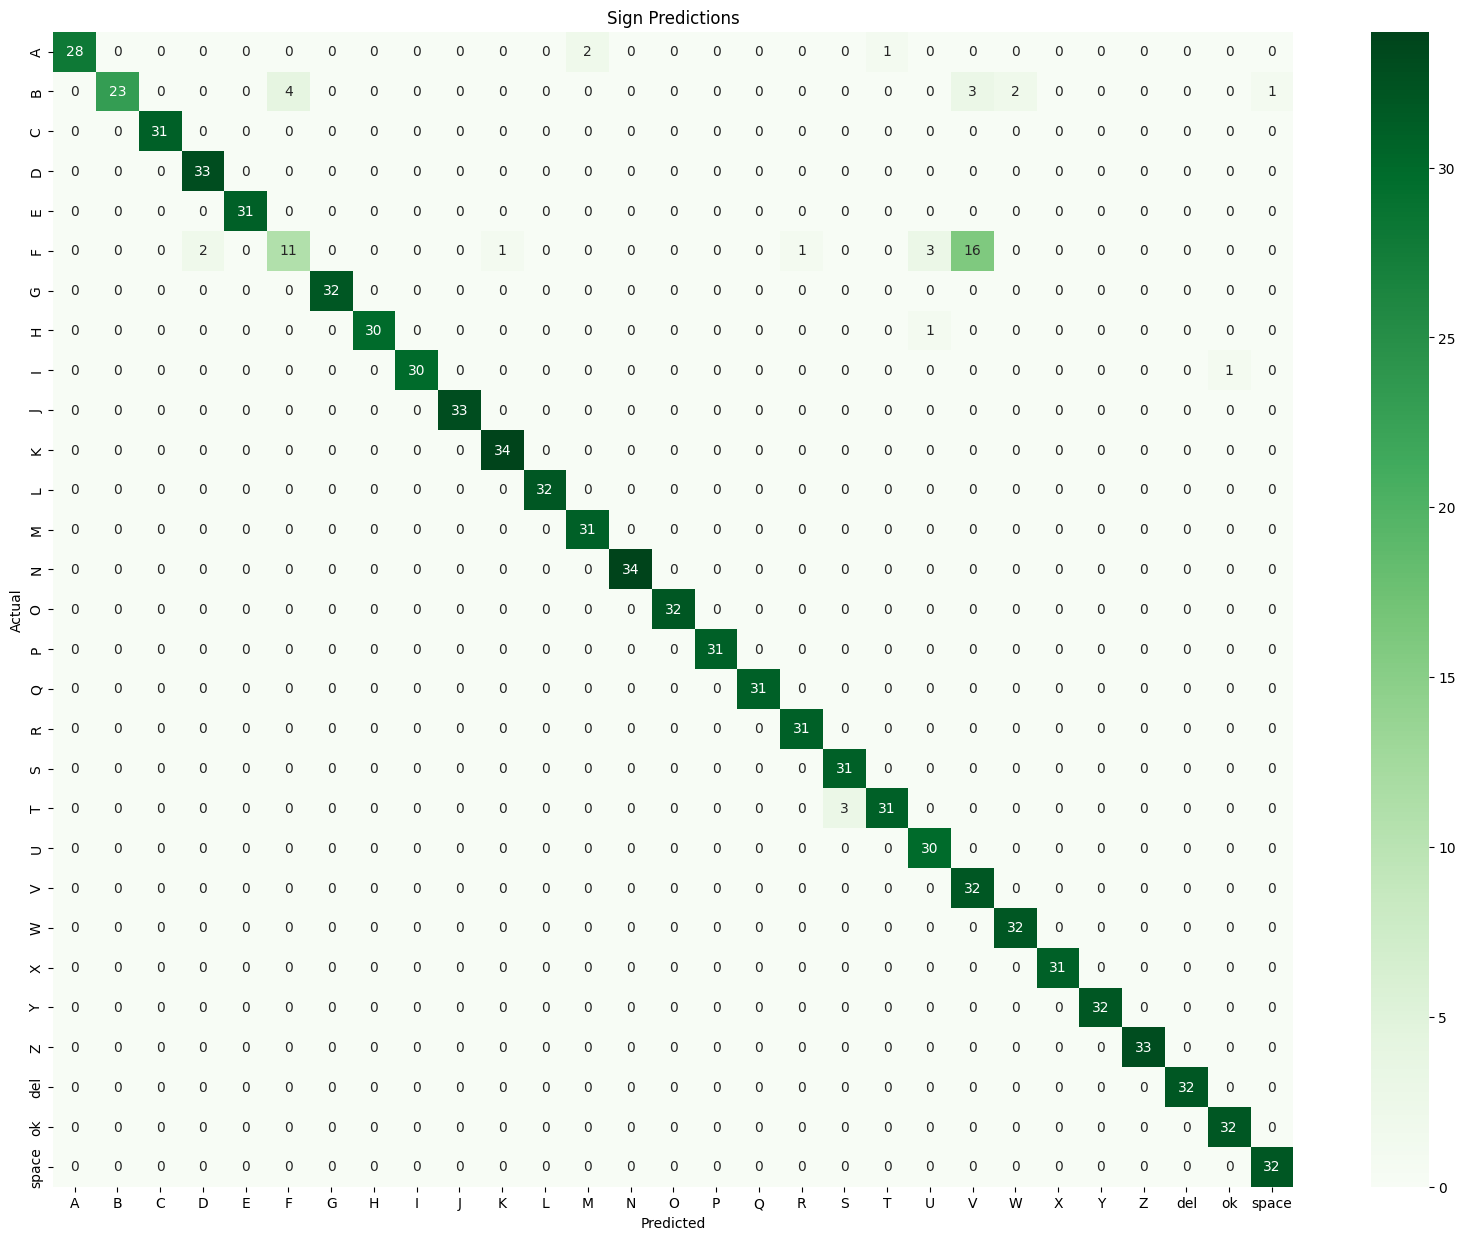

              precision    recall  f1-score   support

           0       1.00      0.90      0.95        31
           1       1.00      0.70      0.82        33
           2       1.00      1.00      1.00        31
           3       0.94      1.00      0.97        33
           4       1.00      1.00      1.00        31
           5       0.73      0.32      0.45        34
           6       1.00      1.00      1.00        32
           7       1.00      0.97      0.98        31
           8       1.00      0.97      0.98        31
           9       1.00      1.00      1.00        33
          10       0.97      1.00      0.99        34
          11       1.00      1.00      1.00        32
          12       0.94      1.00      0.97        31
          13       1.00      1.00      1.00        34
          14       1.00      1.00      1.00        32
          15       1.00      1.00      1.00        31
          16       1.00      1.00      1.00        31
          17       0.97    

In [3]:

z


In [ ]:
import os 


label=['A','B','C','D','E','F','G','H','I','J','K','L','O','R','S','U','V','W','X','Y','Z','del','ok','space']

for lab in label:
    os.mkdir(f'/home/maries/Development/Project_OWSLT/datasets/ASL Letters RT/{lab}')


In [ ]:


name = 'nameis'

for i in range(2):
    end = name[len(name)-1]
    name = name.removesuffix(end)
print(name)



In [4]:
import customtkinter as ctk
from PIL import Image, ImageTk
import cv2
import numpy as np
import tensorflow as tf
import mediapipe as mp
from collections import deque
import pyttsx3

# Set the appearance and theme
ctk.set_appearance_mode("dark")
ctk.set_default_color_theme("blue")

class SignLanguageApp:
    def __init__(self, window):
        self.window = window
        self.window.configure(expand=True,fill='both')
        self.window.title("Modern Sign Language Detector")
        self.window.geometry("1080x700")

        # Initialize TTS engine once
        self.engine = pyttsx3.init()
        self.engine.setProperty('rate', 150)
        voices = self.engine.getProperty('voices')
        self.engine.setProperty('voice', voices[0].id) # Female voice

        # Load Model (Add your logic here)
        self.letter_model = tf.keras.models.load_model('/home/maries/Development/Project_OWSLT/models/letter_modelV2.keras')
        self.labels = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T','U','V','W','X','Y','Z','del','ok','space']
        
        self.mp_hand = mp.solutions.hands
        self.hand = self.mp_hand.Hands(min_detection_confidence=0.5, min_tracking_confidence=0.5, max_num_hands=1)
        
        # Variables 
        self.sequence_frames = deque(maxlen=30)
        self.display_text = ""
        self.pre_label = ""
        self.percent = 0

        # --- GUI LAYOUT ---
        self.frame_upper = ctk.CTkFrame(window)
        self.frame_upper.grid(row=0 , column=0, padx=20, pady=20,sticky='we')
        self.frame_lower = ctk.CTkFrame(window)
        self.frame_lower.grid(row=1 , column=0, padx=20, pady=20,sticky='we')
        
    
        
        # Main Video Frame
        self.video_label = ctk.CTkLabel(self.frame_upper, text="") 
        self.video_label.grid(row=0 , column=0, padx=10, pady=20)
        
        # Skeleton View Frame
        self.crop_label = ctk.CTkLabel(self.frame_upper, text="", fg_color="black")
        self.crop_label.grid(row=0 , column=1, padx=10, pady=20)
        
        # Sentence Display
        self.sentence_frame = ctk.CTkFrame(self.frame_lower)
        self.sentence_frame.pack(expand = True,fill='both',padx=10, pady=10)
        
        self.text_display = ctk.CTkLabel(self.sentence_frame, text=" Sentence: ", font=ctk.CTkFont(family="Helvetica", size=60), text_color="#3b8ed0")
        self.text_display.grid(row=0,column=0,padx=10,pady=10)
        
        # Prediction Status
        self.prediction_frame = ctk.CTkFrame(self.frame_lower)
        self.prediction_frame.pack(expand = True,fill='both',padx=10, pady=10)
        
        self.status_label = ctk.CTkLabel(self.prediction_frame, text="Predicted: None", font=ctk.CTkFont(family="Helvetica", size=60))
        self.status_label.grid(row=1,column=0,padx=10,pady=10)

        # Buttons Container
        self.button_frame = ctk.CTkFrame(self.frame_lower, fg_color="transparent")
        self.button_frame.pack(padx=10, pady=10)

        self.btn_clear = ctk.CTkButton(self.button_frame, text="Clear Text", fg_color="#E74C3C", hover_color="#C0392B", command=self.clear_text)
        self.btn_clear.grid(row=0 , column=0, padx=20, pady=20)

        self.btn_t2v = ctk.CTkButton(self.button_frame, text="Speak Text", command=self.cvt_t2v)
        self.btn_t2v.grid(row=0 , column=1, padx=20, pady=20,columnspan=3)

        

        # Camera Setup
        self.vid = cv2.VideoCapture(0)
        self.update_frame()
        self.window.protocol("WM_DELETE_WINDOW", self.on_closing)

    def clear_text(self):
        self.display_text = ""
        self.sequence_frames.clear()
        self.text_display.configure(text="Sentence: ")

    def cvt_t2v(self):
        # Using say() without re-initializing the engine improves performance
        if self.display_text.strip():
            self.engine.say(self.display_text)
            self.engine.runAndWait()

    def update_frame(self):
        res, frame = self.vid.read()
        if res:
            frame = cv2.flip(frame, 1)
            croped_frame = np.zeros((224, 224, 3), dtype=np.uint8)
            
            rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            
            # Logic for MediaPipe/Prediction goes here...
            # (Keeping your original logic but updating the labels)
            hand_result = self.hand.process(rgb_frame)

            if hand_result.multi_hand_landmarks:
                for han in hand_result.multi_hand_landmarks:
                    # normalize_landmarks and draw_hand_skeleton 
                    nmr_lm = normalize_landmarks(han.landmark, 224, 224)
                    draw_hand_skeleton(croped_frame, nmr_lm)
                
                croped_arr = np.expand_dims(croped_frame, axis=0)
                croped_arr = tf.keras.applications.resnet50.preprocess_input(croped_arr)
            
                predict = self.letter_model.predict(croped_arr, verbose=0)
                self.pre_label = self.labels[np.argmax(predict)]
                self.percent = int(np.max(predict[0] * 100))
                self.sequence_frames.append(self.pre_label)

        
            if len(self.sequence_frames) >= 20 and self.percent >= 70:
                extracted = self.sequence_frames.pop()
                if extracted == 'del':
                    self.display_text = self.display_text[:-1]
                elif extracted == 'space':
                    self.display_text += ' '
                elif extracted == 'ok':
                    self.cvt_t2v()
                else: 
                    self.display_text += extracted
                self.sequence_frames.clear()
            
            # Update GUI Labels using .configure()
            self.text_display.configure(text=f"Sentence: {self.display_text}",font=ctk.CTkFont(family="Helvetica", size=160))
            self.status_label.configure(text=f"Predicted: {self.pre_label} ({self.percent}%)",font=ctk.CTkFont(family="Helvetica", size=160))

            # Convert to CTkImage for better scaling
            img_main = Image.fromarray(rgb_frame)
            ctk_img_main = ctk.CTkImage(light_image=img_main, dark_image=img_main, size=(640, 480))
            self.video_label.configure(image=ctk_img_main)
            
            img_crop = Image.fromarray(cv2.cvtColor(croped_frame, cv2.COLOR_BGR2RGB))
            ctk_img_crop = ctk.CTkImage(light_image=img_crop, dark_image=img_crop, size=(224, 224))
            self.crop_label.configure(image=ctk_img_crop)
            

        self.window.after(1, self.update_frame)

    def on_closing(self):
        self.vid.release()
        self.window.destroy()

if __name__ == "__main__":
    root = ctk.CTk()
    app = SignLanguageApp(root)
    root.mainloop()

I0000 00:00:1771410689.517344    4266 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1771410689.518306  204514 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.3.5), renderer: Mesa Intel(R) UHD Graphics (TGL GT1)
W0000 00:00:1771410689.532737  204505 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1771410689.541522  204504 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
invalid command name "140333598747328update"
    while executing
"140333598747328update"
    ("after" script)
invalid command name "140336783673728check_dpi_scaling"
    while executing
"140336783673728check_dpi_scaling"
    ("after" script)
invalid command name "140333598682880update_frame"
    while executing
"140333598682880update_frame"
    ("after" script)
2026-02-18 16:

land to npy  

In [28]:
import mediapipe as mp
import cv2
import numpy as np
import os,uuid

mp_draw = mp.solutions.drawing_utils
mp_hand = mp.solutions.hands
hand = mp_hand.Hands(min_detection_confidence=0.5,min_tracking_confidence=0.5,max_num_hands=2)
mp_draw_st = mp.solutions.drawing_styles

label=['A','B','C','D','E','F','G','H','I','J','K','L','O','R','S','U','V','W','X','Y','Z','del','ok','space']
#label=['0','1','2','3','4','5','6','7','8','9','del','ok','space']
outputpath='/home/maries/Development/final year project/backend/res/Videos/a/'
lab_count=0
cam = cv2.VideoCapture(0)
counter=0
no_frames=30
nparr =[] 
while True:
    res,frame = cam.read()
    frame=cv2.flip(frame,1)
    frame= cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    croped_frame = np.zeros((224,224,3),dtype=np.uint8)
    hand_result = hand.process(frame)
    frame= cv2.cvtColor(frame,cv2.COLOR_RGB2BGR)
    
    if hand_result.multi_hand_landmarks:
        
        if counter < 30 and cv2.waitKey(3) & 0xff == ord('c'):
            counter+=1
            for han in hand_result.multi_hand_landmarks:
                # mp_draw.draw_landmarks(frame,han,mp_hand.HAND_CONNECTIONS)
                normal_lm = normalize_landmarks(han.landmark,224,224)
                nparr.append(normal_lm)
                draw_hand_skeleton(croped_frame,normal_lm)
                cv2.imshow('crop',croped_frame)
        elif counter ==30 :
            counter = 0
            np.save(f'/home/maries/Development/final year project/backend/res/Videos/{label[3]}/{lab_count}.npy',np.array(nparr))
            print(f'file {lab_count } saved successfully!!')
            lab_count+=1
            nparr.clear()
            continue
    
    if cv2.waitKey(3) & 0xff == ord('q'):
        break
    cv2.putText(frame,f'class:{label[3]}',(10,50),cv2.FONT_HERSHEY_COMPLEX,1.5,(0,0,255),2)
    cv2.imshow('mp',frame)
#saving the keypoints
cam.release()
cv2.destroyAllWindows()






I0000 00:00:1769866978.902909   22926 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1769866978.904508   57106 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.3.4), renderer: Mesa Intel(R) UHD Graphics (TGL GT1)
W0000 00:00:1769866978.922693   57096 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1769866978.937236   57092 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


file 0 saved successfully!!
file 1 saved successfully!!
file 2 saved successfully!!
file 3 saved successfully!!
file 4 saved successfully!!
file 5 saved successfully!!
file 6 saved successfully!!
file 7 saved successfully!!
file 8 saved successfully!!
file 9 saved successfully!!
file 10 saved successfully!!
file 11 saved successfully!!
file 12 saved successfully!!
file 13 saved successfully!!
file 14 saved successfully!!
file 15 saved successfully!!
file 16 saved successfully!!
file 17 saved successfully!!
file 18 saved successfully!!
file 19 saved successfully!!
file 20 saved successfully!!
file 21 saved successfully!!
file 22 saved successfully!!
file 23 saved successfully!!
file 24 saved successfully!!
file 25 saved successfully!!
file 26 saved successfully!!
file 27 saved successfully!!
file 28 saved successfully!!
file 29 saved successfully!!
file 30 saved successfully!!
